<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/05_variable_stars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 · Variable stars: periods from combined ZTF + LSST light curves

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~30 min

Periodic variables (RR Lyrae, Cepheids, δ Scuti, eclipsing binaries, long-period variables) are standard candles,
tracers of Galactic structure and laboratories of stellar physics. Their most important number is the **period**.

ZTF and LSST are complementary for period finding:

| | ZTF | LSST (so far) |
|---|---|---|
| baseline | ~8 years (2018–2026) | ~6 months |
| bands | g, r, (i) | u, g, r, i, z, y |
| depth | ~20.5 mag | ~24.5 mag |
| observing site | Palomar (California) | Cerro Pachón (Chile) |

**Contents**
1. One RR Lyrae star, three objects: ZTF17aabhbva and its two LSST diaObjects
2. ALeRCE features: ZTF says 0.489 d, LSST says 0.978 d. Who is right?
3. Sampling, window functions and aliases
4. Breaking the alias: multi-harmonic fits
5. Sanity checks: VSX, Simbad and Gaia
6. A sample: periodic variables in COSMOS seen by both surveys
7. The Bailey diagram
8. Exercises

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py
    !mkdir -p data
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/vs_sample.csv

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.timeseries import LombScargle
from astropy.coordinates import SkyCoord
import astropy.units as u

import alerce_ms as am

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 1. One RR Lyrae star, three objects

`ZTF17aabhbva` is one of the three COSMOS examples. Let us find all objects, in both surveys, within 2″:

In [2]:
star = am.get_object("ZTF17aabhbva", "ztf")
ra, dec = star["meanra"], star["meandec"]
counterparts = am.find_counterparts(ra, dec, radius_arcsec=2)
counterparts

,name,survey,ra,dec,sid,oid,sep_arcsec
0,ZTF17aabhbva,ztf,150.170670,1.368242,0,36028933560318190,0.000000
1,313893021775560722,lsst,150.170671,1.368230,1,313893021775560722,0.041680
2,313888627082919999,lsst,150.170671,1.368230,1,313888627082919999,0.042963


**One star, three objects**: one in ZTF and *two* LSST diaObjects, both within 0.05″ of the ZTF position. Remember
rule 2 of notebook 01: there is no cross-survey association, and even within LSST the association of sources into
diaObjects is done by Rubin's pipeline, which can occasionally split one star into two objects. The Rubin
`lsst_dia_object` table tells us how many sources were associated with each one:

In [3]:
ztf_oid = am.ztf_name_to_oid("ZTF17aabhbva")
lsst_a, lsst_b = 313888627082919999, 313893021775560722
am.tap_query(f"""
    SELECT oid, ra, dec, ndiasources, validitystartmjdtai
    FROM alerce_tap.lsst_dia_object
    WHERE oid IN ({lsst_a}, {lsst_b})
""")

,oid,ra,dec,ndiasources,validitystartmjdtai
0,313888627082919999,150.170658,1.368241,551,61099.319810
1,313893021775560722,150.170660,1.368241,720,61205.990475


What do the classifiers say? For ZTF we have the light-curve classifier (hierarchical: top level, then the
periodic branch); for LSST, the Rubin stamp classifier, which only looks at the first image cut-outs.

In [4]:
p_ztf = am.get_probabilities(ztf_oid, 0).query("ranking <= 2")
p_lsst = am.get_probabilities(lsst_a, 1).query("ranking <= 2")
pd.concat([p_ztf, p_lsst])[["survey_name", "oid", "classifier_name", "class_name", "probability", "ranking"]]

,survey_name,oid,classifier_name,class_name,probability,ranking
0,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot,RRLab,0.396240,1
1,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot,CV/Nova,0.222720,2
21,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_periodic,RRLab,0.762000,1
22,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_periodic,CEP,0.098000,2
30,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_stochastic,CV/Nova,0.696000,1
31,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_stochastic,Blazar,0.130000,2
36,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_top,Periodic,0.520000,1
37,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_top,Stochastic,0.320000,2
39,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_transient,SLSN,0.296000,1
40,ZTF,36028933560318190,lc_classifier_BHRF_forced_phot_transient,TDE,0.160000,2


* The ZTF light-curve classifier: top level **Periodic** (0.52), and **RRLab** (0.76) within the periodic branch.
  Note that *every* branch gives probabilities for *every* object (the transient branch says SLSN!): always read the
  branch that matches the top-level class.
* The ZTF stamp classifiers, which only see the first alert's cut-outs, say **AGN**: a faint point source
  varying on a difference image looks the same for a quasar and a star.
* The Rubin stamp classifiers say **VS** (variable star) with high probability.

## 2. ALeRCE features: two different periods

ALeRCE computes a multiband period (`Multiband_period`) and per-band periods (`Period_band`) for every object.
`PPE` is a measure of how significant the periodogram peak is.

In [5]:
names = ["Multiband_period", "Period_band", "PPE"]
feats = pd.concat([am.get_features(oid, sid, names) for oid, sid in
                   [(ztf_oid, 0), (lsst_a, 1), (lsst_b, 1)]])
feats.pivot_table(index=["survey_name", "oid"], columns=["feature_name", "band_name"],
                  values="feature_value").round(4)

feature_name                       Multiband_period             PPE         Period_band                                        
band_name                                                gr              gr           g       i       r       u       y       z
survey_name     oid                                                                                                            
LSST DIA Object 313888627082919999           0.9779     NaN  0.0313     NaN      0.9779  0.4894  0.9605     NaN  0.9870  0.9779
                313893021775560722           0.9582     NaN  0.0107     NaN      0.9582  0.4887  0.9582  0.2577  0.0592  0.9576
ZTF             36028933560318190               NaN  0.4889     NaN  0.0327      0.4889     NaN  0.4889     NaN     NaN     NaN

* ZTF: **0.4889 d** in g, r and multiband.
* LSST: the multiband period is **~0.96–0.98 d**, about **twice** the ZTF value; only the i band finds 0.489 d.

Which one is right? Let us look at the data.

In [6]:
lc_ztf = am.get_lightcurve(ztf_oid, 0)
lc_a = am.get_lightcurve(lsst_a, 1)
lc_b = am.get_lightcurve(lsst_b, 1)
lc_lsst = pd.concat([lc_a, lc_b])
lc_all = pd.concat([lc_ztf, lc_lsst])

for name, lc in [("ZTF", lc_ztf), ("LSST A", lc_a), ("LSST B", lc_b)]:
    print(f"{name:7s} {len(lc):5d} points, {np.unique(np.floor(lc.mjd)).size:4d} nights, "
          f"MJD {lc.mjd.min():.0f}–{lc.mjd.max():.0f}, bands {sorted(lc.band_name.unique())}")

ZTF       820 points,  313 nights, MJD 58464–61333, bands ['g', 'i', 'r']
LSST A   1523 points,   20 nights, MJD 61032–61099, bands ['g', 'i', 'r', 'u', 'y', 'z']
LSST B   1914 points,   60 nights, MJD 61032–61206, bands ['g', 'i', 'r', 'u', 'y', 'z']


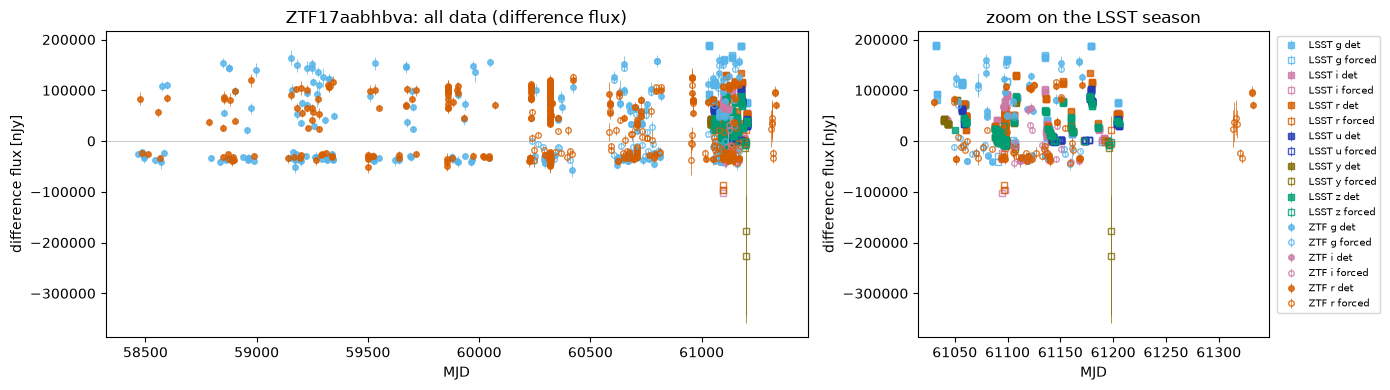

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
am.plot_lightcurve(lc_all, flux="diff", ax=axes[0], title="ZTF17aabhbva: all data (difference flux)")
axes[0].get_legend().remove()
am.plot_lightcurve(lc_all[lc_all.mjd > 61030], flux="diff", ax=axes[1], title="zoom on the LSST season")
plt.tight_layout();

We use the **difference flux** for period finding. For a variable star it is the star's flux minus its flux in the
template image, so it can be negative, and every survey and band has its own zero point. That does not matter for
the period: we will subtract the median of each survey-band. (The direct-image `scienceflux` of LSST diaObject B
has a group of forced-photometry points that are ~1 mag too faint; difference fluxes do not have this problem.
Always look at your data!)

## 3. Sampling, window functions and aliases

A ground-based telescope observes at night, so the times are clumped around the same time of the day.
Let us look at *when* during the (UTC) day each survey observed this star:

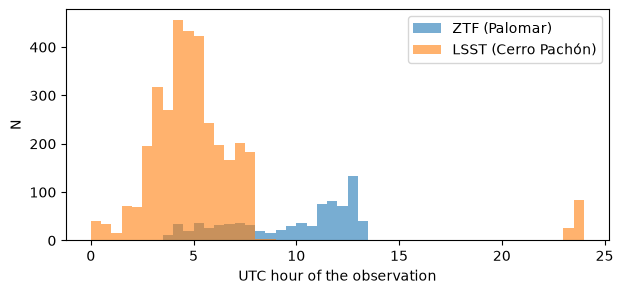

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(24 * (lc_ztf.mjd % 1), bins=48, range=(0, 24), alpha=0.6, label="ZTF (Palomar)")
ax.hist(24 * (lc_lsst.mjd % 1), bins=48, range=(0, 24), alpha=0.6, label="LSST (Cerro Pachón)")
ax.set_xlabel("UTC hour of the observation")
ax.set_ylabel("N")
ax.legend();

Now think about a star with $P = 0.4889$ d ≈ 11.7 h. Observing it at the same time every night is almost like
observing it every two cycles: we see nearly the same phase night after night, and the phase only drifts slowly.

The **spectral window** (the periodogram of the sampling pattern alone, i.e. of a constant signal) shows the
frequencies "imprinted" by the sampling. If the true frequency is $f$, the periodogram will also show peaks at
$|f \pm f_\mathrm{window}|$: these are **aliases**.

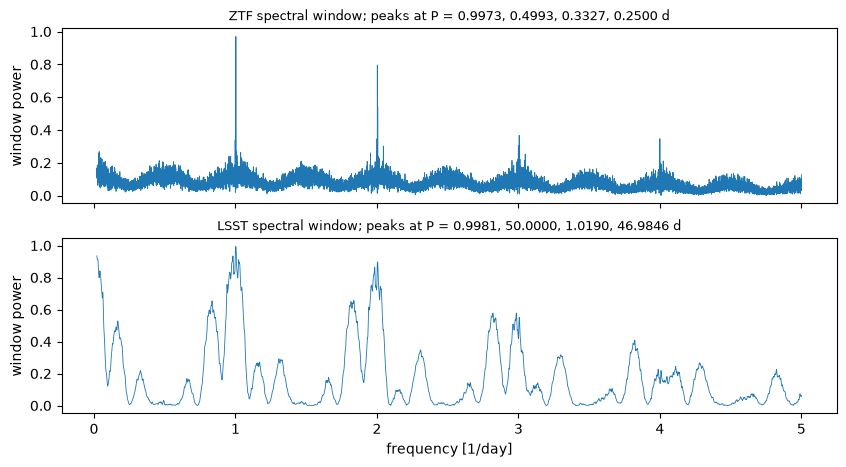

In [9]:
BANDS = ["ZTF g", "ZTF r", "LSST g", "LSST r", "LSST i", "LSST z"]


def prepare(lc, min_points=15, bands=BANDS):
    """Clean a light curve from am.get_lightcurve for period finding.

    * uses the difference flux and removes the median of each survey-band ("ZTF g", "LSST g", ...):
      filters and templates differ, so every survey-band gets its own zero point;
    * keeps the well-sampled bands (ZTF g, r; LSST g, r, i, z) with >= min_points points;
    * scales each survey-band to unit scatter so that all bands carry similar weight."""
    d = lc[np.isfinite(lc.diff_flux) & np.isfinite(lc.diff_flux_err) & (lc.diff_flux_err > 0)].copy()
    d["label"] = d.survey.str.upper() + " " + d.band_name
    d = d[d.label.isin(bands)]
    med = d.groupby("label").diff_flux.transform("median")
    mad = 1.4826 * (d.diff_flux - med).abs().groupby(d.label).transform("median")
    d = d[(d.diff_flux - med).abs() < 8 * mad + 1]          # drop gross outliers
    d = d[d.groupby("label").diff_flux.transform("size") >= min_points]
    scale = d.groupby("label").diff_flux.transform("std")
    d["y"] = (d.diff_flux - d.groupby("label").diff_flux.transform("median")) / scale
    d["dy"] = d.diff_flux_err / scale
    return d


def periodogram(d, fmin=0.1, fmax=20.0, samples_per_peak=5):
    """Classic (single-sinusoid) Lomb-Scargle periodogram of a prepared light curve."""
    ls = LombScargle(d.mjd, d.y, d.dy)
    return ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax, samples_per_peak=samples_per_peak)


def window(d, fmin=0.02, fmax=5.0):
    """Spectral window: periodogram of a constant signal sampled at the same times."""
    ls = LombScargle(d.mjd, np.ones(len(d)), fit_mean=False, center_data=False)
    return ls.autopower(minimum_frequency=fmin, maximum_frequency=fmax, samples_per_peak=5)


def top_peaks(freq, power, n=8, min_sep=0.01):
    """Frequencies of the n highest, well separated peaks (descending power)."""
    out = []
    for i in np.argsort(power)[::-1]:
        if all(abs(freq[i] - f) > min_sep * f for f in out):
            out.append(freq[i])
        if len(out) == n:
            break
    return np.array(out)


d_ztf, d_lsst, d_all = prepare(lc_ztf), prepare(lc_lsst), prepare(lc_all)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, d, name in [(axes[0], d_ztf, "ZTF"), (axes[1], d_lsst, "LSST")]:
    f, p = window(d)
    ax.plot(f, p, lw=0.6)
    ax.set_ylabel("window power")
    ax.set_title(f"{name} spectral window; peaks at P = " +
                 ", ".join(f"{1/x:.4f}" for x in top_peaks(f, p, 4)) + " d", fontsize=9)
axes[1].set_xlabel("frequency [1/day]");

Both windows peak at **1 cycle/day** and its harmonics (2, 3, 4 c/d): night-to-night sampling. The ZTF peaks are
sharp because its baseline is 8 years long. The LSST window, from a single ~5-month season with groups of
consecutive nights, has **broad** peaks, side lobes around each integer frequency, and power at very low
frequencies (the ~50 d gaps between groups of nights).

Now the periodograms of the star itself, for ZTF only, LSST only and both together (red lines: the four highest
peaks):

ZTF         N =   788  top LS periods: [0.48888 0.95896 0.32806 0.24699]
LSST (A+B)  N =  3129  top LS periods: [0.95967 0.48912 0.97896 0.49439]


ZTF + LSST  N =  3917  top LS periods: [0.48888 0.95999 0.32806 0.97953]


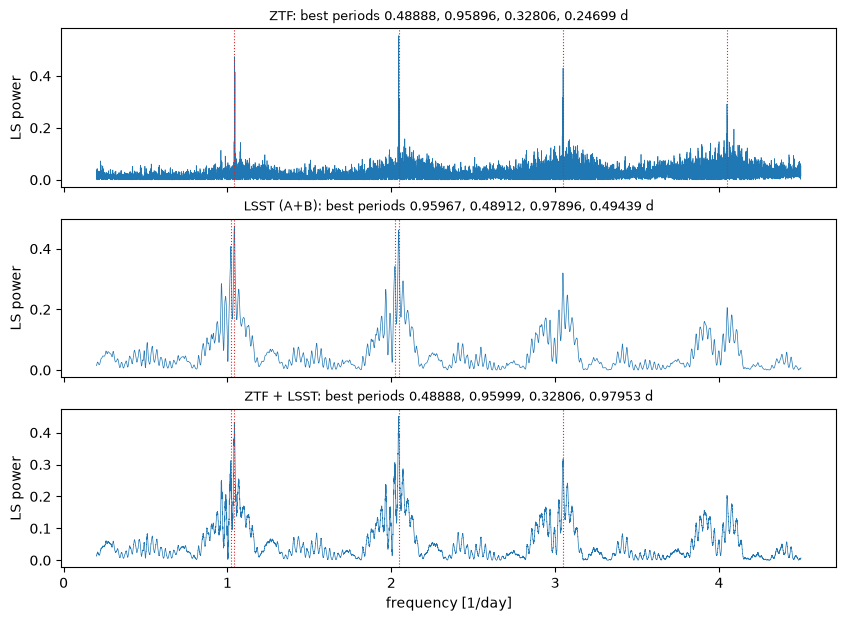

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, d, name in [(axes[0], d_ztf, "ZTF"), (axes[1], d_lsst, "LSST (A+B)"), (axes[2], d_all, "ZTF + LSST")]:
    f, p = periodogram(d, fmin=0.2, fmax=4.5)
    peaks = top_peaks(f, p, 4)
    ax.plot(f, p, lw=0.5)
    for x in peaks:
        ax.axvline(x, color="C3", ls=":", lw=0.8)
    ax.set_ylabel("LS power")
    ax.set_title(f"{name}: best periods " + ", ".join(f"{1/x:.5f}" for x in peaks) + " d", fontsize=9)
    print(f"{name:11s} N = {len(d):5d}  top LS periods:", np.round(1 / peaks, 5))
axes[2].set_xlabel("frequency [1/day]");

* **ZTF alone** puts the highest peak at 0.48887 d, with its 1-day alias at 0.959 d ($1/0.959 \approx 1/0.4889 - 1$)
  close behind.
* **LSST alone** puts the highest peak at the 1-day alias, 0.960 d, followed by 0.489 d and by 0.979 d ≈ 2P.
* **ZTF + LSST** recovers 0.48888 d, but the alias peaks are almost as high.

Every periodogram has the same family of peaks; only their *heights* change. With one survey you could easily pick
the wrong one. How can we decide from the data? Let us fold the light curves at the competing periods:

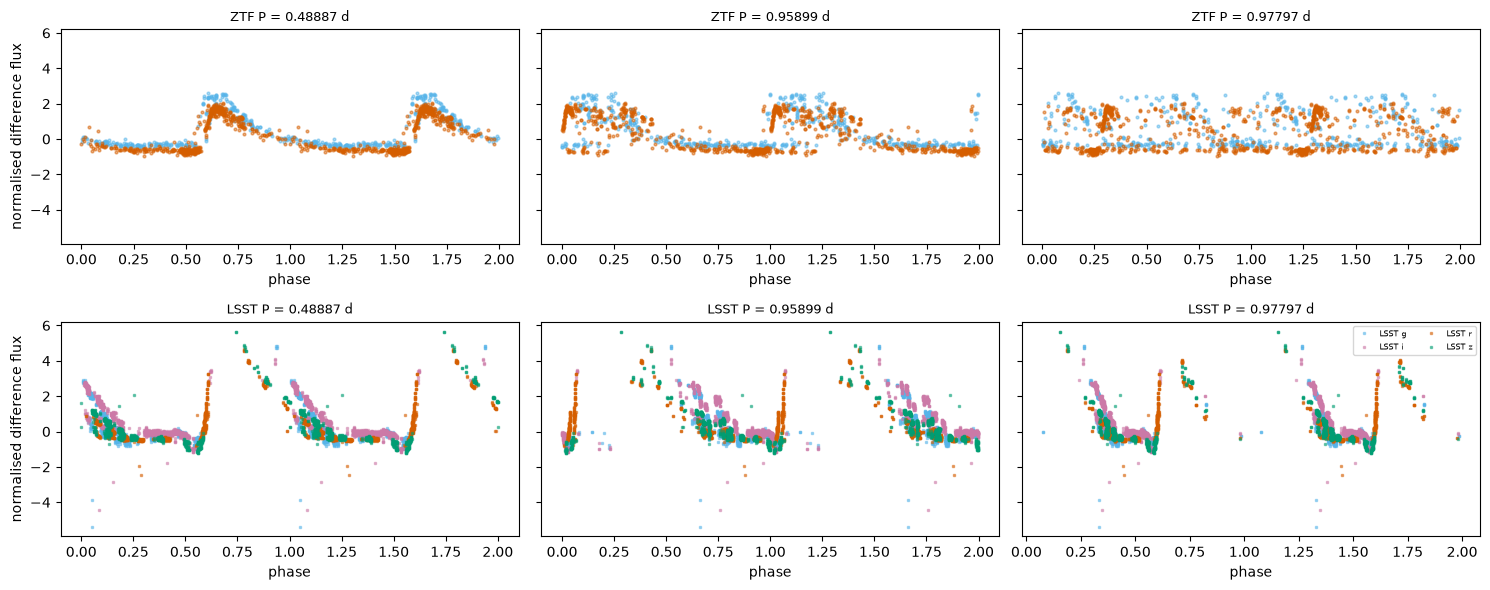

In [11]:
def plot_fold(d, period, ax, title=""):
    for label, g in d.groupby("label"):
        survey, band = label.split()
        phase = (g.mjd / period) % 1
        for shift in (0, 1):
            ax.plot(phase + shift, g.y, am.SURVEY_MARKERS[survey.lower()], ms=2, alpha=0.5,
                    color=am.BAND_COLORS[band], label=label if shift == 0 else None)
    ax.set_title(f"{title} P = {period:.5f} d", fontsize=9)
    ax.set_xlabel("phase")


fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharey=True)
for row, (d, name) in enumerate([(d_ztf, "ZTF"), (d_lsst, "LSST")]):
    for col, period in enumerate([0.48887, 0.95899, 0.97797]):
        plot_fold(d, period, axes[row, col], name)
axes[0, 0].set_ylabel("normalised difference flux")
axes[1, 0].set_ylabel("normalised difference flux")
axes[1, 2].legend(fontsize=6, ncol=2, loc="upper right")
plt.tight_layout();

* At **0.48887 d** both surveys show one clean RR Lyrae cycle: a fast rise and a slow decline (an RRab star).
  Note the gaps in the LSST fold (e.g. near the maximum): the "same time every night" sampling leaves phases
  unobserved.
* At **0.978 d ≈ 2P**, LSST shows a single rise per cycle and an empty half: because 2P is almost exactly one day,
  a telescope that observes at the same time every night only ever sees *one* of the two pulsations. LSST alone
  cannot tell P from 2P this way. ZTF, whose phases drift over 8 years, turns into a mess.
* At **0.959 d** (the 1-day alias) both folds are messy.

## 4. Breaking the alias: multi-harmonic fits

Lomb-Scargle fits a **single sinusoid**. RR Lyrae stars, Cepheids and eclipsing binaries are far from sinusoidal,
so a sinusoid can fit an alias almost as well as the true period. A better test is to fit, at each candidate period,
a **Fourier series with several harmonics** (independently for each survey-band) and compare the χ²:

$$ m(t) = a_0 + \sum_{k=1}^{4} \left[ a_k \sin\left(\frac{2\pi k t}{P}\right) + b_k \cos\left(\frac{2\pi k t}{P}\right)\right] $$

In [12]:
def fourier_chi2(d, period, nterms=4):
    """Reduced chi^2 of a Fourier series with `nterms` harmonics fitted to every survey-band."""
    chi2, dof = 0.0, 0
    for _, g in d.groupby("label"):
        phase = 2 * np.pi * g.mjd.values / period
        cols = [np.ones_like(phase)]
        for k in range(1, nterms + 1):
            cols += [np.sin(k * phase), np.cos(k * phase)]
        X = np.array(cols).T / g.dy.values[:, None]
        y = g.y.values / g.dy.values
        coef, *_ = np.linalg.lstsq(X, y, rcond=None)
        chi2 += np.sum((y - X @ coef) ** 2)
        dof += len(y) - X.shape[1]
    return chi2 / max(dof, 1)


candidates = [0.48887, 0.95899, 0.97797, 1.03949, 0.32806]
pd.DataFrame({name: [fourier_chi2(d, P) for P in candidates]
              for d, name in [(d_ztf, "ZTF"), (d_lsst, "LSST"), (d_all, "ZTF+LSST")]},
             index=pd.Index(candidates, name="trial period [d]")).round(1)

,ZTF,LSST,ZTF+LSST
trial period [d],,,
0.48887,6.9,264.8,213.4
0.95899,32.2,336.6,275.9
0.97797,56.5,325.6,272.0
1.03949,72.6,564.5,466.4
0.32806,32.7,399.6,326.5


With four harmonics the true period, **0.48887 d, has the lowest χ² in ZTF, in LSST and in the combination**.
(The absolute χ² values for LSST are large because its error bars are tiny compared with the residual
systematics; only the *relative* values matter here.)

Let us wrap this in a two-step period finder that we can apply to any star:
1. **candidates**: the top Lomb-Scargle peaks of each survey, plus their simplest relatives: $f/2$ (eclipsing
   binaries often show up at P/2 because their two eclipses look alike), $2f$, and the 1-day aliases $|f \pm 1|$;
2. **score**: for each survey, the multi-harmonic χ² divided by its minimum over the candidates; the scores of the
   surveys are added. This way LSST, with many more points, cannot drown ZTF (and vice versa), and a survey with no
   useful signal (a flat χ²) does not change the ranking.

In [13]:
def find_period(lc, fmin=0.1, fmax=20.0, ncand=8, nterms=4):
    """Return (best_period, lomb_scargle_period, table_of_candidates).
    Periods at the long edge of the grid (> 0.99 / fmin) are trends, not periods: returned as NaN."""
    d = prepare(lc)
    peaks = np.concatenate([top_peaks(*periodogram(ds, fmin, fmax), ncand) for _, ds in d.groupby("survey")])
    cands = np.concatenate([peaks, peaks / 2, 2 * peaks, np.abs(peaks - 1), peaks + 1])
    cands = np.unique(np.round(cands[(cands >= fmin) & (cands <= fmax)], 8))
    table = pd.DataFrame({"period": 1 / cands})
    for survey, ds in d.groupby("survey"):
        table[f"chi2_{survey}"] = [fourier_chi2(ds, 1 / f, nterms) for f in cands]
    chi2_cols = [c for c in table if c.startswith("chi2_")]
    table["score"] = sum(table[c] / table[c].min() for c in chi2_cols)
    table = table.sort_values("score").reset_index(drop=True)
    freq, power = periodogram(d, fmin, fmax)
    best, ls1 = table.period.iloc[0], 1 / freq[np.argmax(power)]
    edge = 0.99 / fmin
    return (np.nan if best > edge else best), (np.nan if ls1 > edge else ls1), table


for name, lc in [("ZTF", lc_ztf), ("LSST", lc_lsst), ("ZTF+LSST", lc_all)]:
    best, ls1, table = find_period(lc)
    print(f"{name:9s} Lomb-Scargle: {ls1:.5f} d   multi-harmonic: {best:.5f} d")

table.head()

ZTF       Lomb-Scargle: 0.48888 d   multi-harmonic: 0.48888 d
LSST      Lomb-Scargle: 0.95956 d   multi-harmonic: 0.48909 d


ZTF+LSST  Lomb-Scargle: 0.48888 d   multi-harmonic: 0.48888 d


,period,chi2_lsst,chi2_ztf,score
0,0.488880,264.494742,4.389691,2.000028
1,0.488880,264.487275,4.459785,2.015968
2,0.977759,331.968984,15.410164,4.765676
3,0.958960,336.360788,31.514572,8.450969
4,1.917920,333.162464,32.366964,8.633057


### How precise is the period?

The width of a periodogram peak is roughly $\delta f \approx 1/T$, where $T$ is the time baseline, so
$\delta P \approx P^2 / T$. ZTF's 8-year baseline makes it far more precise than one LSST season:

In [14]:
P0 = 0.48887
for d, name in [(d_ztf, "ZTF"), (d_lsst, "LSST")]:
    T = d.mjd.max() - d.mjd.min()
    f = np.linspace(1 / P0 - 3 / T, 1 / P0 + 3 / T, 4001)
    p = LombScargle(d.mjd, d.y, d.dy).power(f)
    best = 1 / f[np.argmax(p)]
    print(f"{name:5s} T = {T:6.0f} d   P = {best:.6f} d   expected precision P²/T ≈ {P0**2 / T:.1e} d")

ZTF   T =   2868 d   P = 0.488874 d   expected precision P²/T ≈ 8.3e-05 d
LSST  T =    156 d   P = 0.489066 d   expected precision P²/T ≈ 1.5e-03 d


Today ZTF gives the precise period and LSST adds six bands and depth; after 10 years of LSST the roles will be
shared. Combining both surveys also lets you look for **period changes** (Blazhko effect, evolution) over ~20 years.

## 5. Sanity checks: VSX, Simbad and Gaia

The experimental explorer collects external information around the object:

In [15]:
ext = am.explorer_xmatch("ZTF17aabhbva", "ztf")
ext[ext.sep < 2]

,cat_name,category,name,type,z,z_err,sep,ra,dec
0,Simbad,stellar,SDSS J100040.95+012205.6,RRLyrae,0.000115,0.000016,0.002093,150.170670,1.368242
1,NED,host,WISEA J100040.98+012205.2,*,0.000342,0.000011,0.005727,150.170669,1.368240
2,Gaia DR3,stellar,3834458188103774592,variable star,NaN,NaN,0.006015,150.170669,1.368240
3,VSX,stellar,CSS_J100040.9+012205,RRAB,NaN,NaN,0.557622,150.170520,1.368280


VSX (the AAVSO Variable Star indeX) lists it as **RRAB** (CSS_J100040.9+012205, from the Catalina survey) and
Simbad as an RR Lyrae. Simbad's "z" is the radial velocity in disguise: $v = cz$.

What about Gaia DR3? It is in the `xmatch` table of the ALeRCE database:

In [16]:
gaia = am.get_xmatch(ztf_oid, 0).query("catalog_name == 'GaiaDR3_source'")
gaia[["oid_catalog", "dist", "phot_g_mean_mag", "bp_rp", "parallax", "parallax_error", "pm",
      "phot_variable_flag", "in_qso_candidates", "classprob_dsc_combmod_quasar"]]

,oid_catalog,dist,phot_g_mean_mag,bp_rp,parallax,parallax_error,pm,phot_variable_flag,in_qso_candidates,classprob_dsc_combmod_quasar
1,3834458188103774592,0.004787,18.880117,0.791801,-0.207348,0.262795,0.430584,VARIABLE,True,1.0


Two surprises:
* the parallax is **not significant** (−0.2 ± 0.26 mas), and
* Gaia's classifier gives it **P(quasar) ≈ 1**!

RR Lyrae stars are standard candles: $M_G \approx +0.6$. Let us compute the distance they imply:

In [17]:
G = gaia.phot_g_mean_mag.iloc[0]
M_G = 0.6
mu = G - M_G                                  # ignoring extinction (small at high Galactic latitude)
dist_kpc = 10 ** (mu / 5 + 1) / 1e3
print(f"G = {G:.2f}  ->  distance modulus {mu:.2f}  ->  d ≈ {dist_kpc:.0f} kpc,"
      f" expected parallax ≈ {1 / dist_kpc:.3f} mas")
print(f"Gaia parallax error: {gaia.parallax_error.iloc[0]:.3f} mas")

G = 18.88  ->  distance modulus 18.28  ->  d ≈ 45 kpc, expected parallax ≈ 0.022 mas
Gaia parallax error: 0.263 mas


The star is ~45 kpc away, in the **Galactic halo**, so its parallax (~0.02 mas) is ten times smaller than Gaia's
error. And a faint, blue, variable point source with no measurable parallax or proper motion is exactly what a
quasar looks like to Gaia. The period and light-curve shape from ZTF + LSST settle the question: it is an RR Lyrae.

> 💡 Classifications (including ours) are probabilistic and can be fooled. Combining independent information —
> light-curve shape, period, colours, astrometry, spectra — is what makes them robust.

## 6. A sample: periodic variables in COSMOS seen by both surveys

Now we scale up. COSMOS is a Rubin deep-drilling field, so LSST has many epochs there. Strategy:

1. **one TAP query**: all ZTF objects within 2° whose **top-level class is `Periodic`** and whose best class in the
   periodic branch is known. (Both conditions matter: the periodic branch gives probabilities for *every* object,
   even supernovae — without the top-level condition our SN Ic would sneak in as an "RR Lyrae"!)
2. **one TAP query**: all LSST objects in the same circle with ≥ 20 detections;
3. crossmatch the two lists **locally** with astropy.

Two queries instead of hundreds of cone searches: much faster, and gentle with the server.

In [18]:
RA0, DEC0, RADIUS = 150.12, 2.21, 2.0
cid = am.classifier_id("lc_classifier_BHRF_forced_phot_periodic")
top = am.classifier_id("lc_classifier_BHRF_forced_phot_top")
periodic = am.class_id("lc_classifier_BHRF_forced_phot_top", "Periodic")

ztf_vs = am.tap_query(f"""
    SELECT o.oid, o.meanra, o.meandec, o.n_det, p.class_id, p.probability, t.probability AS p_periodic
    FROM alerce_tap.object AS o
    JOIN alerce_tap.probability AS p ON p.oid = o.oid AND p.sid = o.sid
    JOIN alerce_tap.probability AS t ON t.oid = o.oid AND t.sid = o.sid
    WHERE o.sid = 0 AND o.n_det >= 30
      AND p.classifier_id = {cid} AND p.ranking = 1
      AND t.classifier_id = {top} AND t.class_id = {periodic} AND t.ranking = 1
      AND 1 = CONTAINS(POINT('ICRS', o.meanra, o.meandec), CIRCLE('ICRS', {RA0}, {DEC0}, {RADIUS}))
""")
ztf_vs = am.decode(ztf_vs.assign(classifier_id=cid))

lsst_objs = am.tap_query(f"""
    SELECT oid, meanra, meandec, n_det, n_forced
    FROM alerce_tap.object
    WHERE sid = 1 AND n_det >= 20
      AND 1 = CONTAINS(POINT('ICRS', meanra, meandec), CIRCLE('ICRS', {RA0}, {DEC0}, {RADIUS}))
""")
print(len(ztf_vs), "ZTF periodic variables,", len(lsst_objs), "LSST objects with >= 20 detections")
ztf_vs.class_name.value_counts().to_frame().T

143 ZTF periodic variables, 32095 LSST objects with >= 20 detections


class_name,RSCVn,Periodic-Other,EB/EW,RRLab,EA,RRLc,DSCT
count,58,36,13,12,10,10,4


In [19]:
c_ztf = SkyCoord(ztf_vs.meanra.values * u.deg, ztf_vs.meandec.values * u.deg)
c_lsst = SkyCoord(lsst_objs.meanra.values * u.deg, lsst_objs.meandec.values * u.deg)

idx, sep, _ = c_ztf.match_to_catalog_sky(c_lsst)              # nearest LSST object for each ZTF star
ztf_vs["lsst_oid"] = lsst_objs.oid.values[idx]
ztf_vs["sep_arcsec"] = sep.arcsec

# how many LSST objects lie within 1.5" of each ZTF star?
i_z, i_l, _, _ = c_lsst.search_around_sky(c_ztf, 1.5 * u.arcsec)
ztf_vs["n_lsst"] = np.bincount(i_z, minlength=len(ztf_vs))

matched = ztf_vs[ztf_vs.sep_arcsec < 1.5]
print(f"{len(matched)} of {len(ztf_vs)} ZTF variables have an LSST counterpart within 1.5\"")
print("LSST diaObjects within 1.5\" of each matched ZTF star:", matched.n_lsst.value_counts().sort_index().to_dict())

dup = matched.lsst_oid.duplicated(keep=False)
print(f"{dup.sum()} ZTF objects share their LSST counterpart with another ZTF object")
matched[dup].sort_values("lsst_oid")[["oid", "meanra", "meandec", "n_det", "class_name", "lsst_oid"]].head(6)

70 of 143 ZTF variables have an LSST counterpart within 1.5"
LSST diaObjects within 1.5" of each matched ZTF star: {1: 66, 2: 4}
49 ZTF objects share their LSST counterpart with another ZTF object


,oid,meanra,meandec,n_det,class_name,lsst_oid
10,36028941622232077,150.913491,2.349115,123,Periodic-Other,170028510542299190
80,36028989782902851,150.913353,2.349066,36,Periodic-Other,170028510542299190
20,36028933560004637,151.692841,1.832327,233,Periodic-Other,170028511898632325
17,36028989782901002,151.692833,1.832268,50,Periodic-Other,170028511898632325
78,36028941622730972,149.268797,1.232683,62,RSCVn,170028512519389283
41,36028989782902937,149.268960,1.232746,33,RSCVn,170028512519389283


Duplicates go both ways! A star can be split into several LSST diaObjects, and also into several **ZTF** objects:
ZTF fields overlap, and the same star falls on different CCDs with different reference images. When several ZTF
objects share one LSST counterpart, we keep the one with the most detections:

In [20]:
matched = matched.sort_values("n_det", ascending=False).drop_duplicates("lsst_oid")
print(len(matched), "unique stars")
matched.class_name.value_counts().to_frame().T

42 unique stars


class_name,Periodic-Other,RSCVn,EB/EW,RRLab,RRLc,EA,DSCT
count,11,8,7,7,4,4,1


### 6.1 ALeRCE periods in ZTF vs LSST

Download `Multiband_period` for all matched objects, two queries (one per survey) with `IN (...)` lists:

41 stars with periods in both surveys


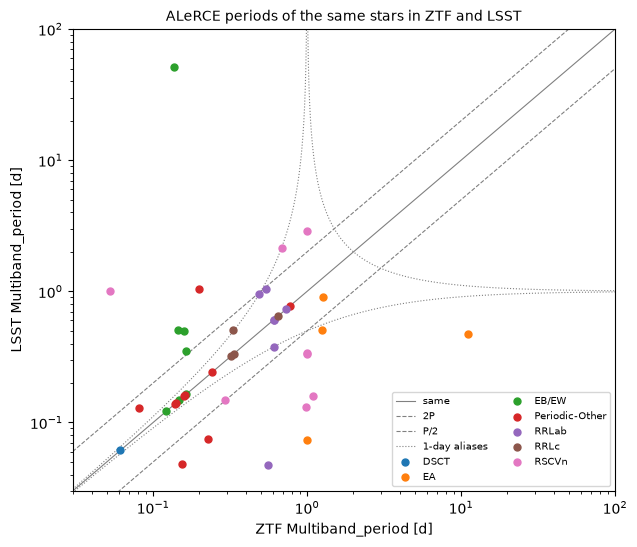

In [21]:
def multiband_period(oids, sid):
    fid = am.feature_ids(sid, ["Multiband_period"])["Multiband_period"]
    df = am.tap_query(f"""
        SELECT oid, feature_value AS period
        FROM alerce_tap.feature
        WHERE sid = {sid} AND feature_id = {fid} AND oid IN ({", ".join(map(str, oids))})
    """)
    return df.set_index("oid").period


matched = matched.copy()
matched["P_ztf"] = matched.oid.map(multiband_period(matched.oid, 0))
matched["P_lsst"] = matched.lsst_oid.map(multiband_period(matched.lsst_oid, 1))
both = matched.dropna(subset=["P_ztf", "P_lsst"])
print(len(both), "stars with periods in both surveys")


def alias_curves(ax, pmin=0.03, pmax=100):
    p = np.logspace(np.log10(pmin), np.log10(pmax), 3000)
    with np.errstate(divide="ignore"):
        curves = {"same": p, "2P": 2 * p, "P/2": p / 2,
                  "1-day aliases": 1 / np.abs(1 / p - 1), None: 1 / (1 / p + 1)}
    for (label, y), ls in zip(curves.items(), ["-", "--", "--", ":", ":"]):
        ax.plot(p, y, ls, color="0.5", lw=0.8, label=label)


def period_scatter(ax, x, y, classes, xlabel, ylabel, title):
    alias_curves(ax)
    for cls in sorted(classes.unique()):
        m = classes == cls
        ax.scatter(x[m], y[m], s=25, label=cls, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(0.03, 100); ax.set_ylim(0.03, 100)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title, fontsize=10)


fig, ax = plt.subplots(figsize=(7, 6))
period_scatter(ax, both.P_ztf, both.P_lsst, both.class_name, "ZTF Multiband_period [d]",
               "LSST Multiband_period [d]", "ALeRCE periods of the same stars in ZTF and LSST")
ax.legend(fontsize=7, ncol=2);

Let us label each pair with the relation between the two periods:

In [22]:
def relation(p, p_ref, tol=0.01):
    """How is period p related to the reference period p_ref?"""
    if not (np.isfinite(p) and np.isfinite(p_ref)):
        return "no period"
    r = p / p_ref
    if abs(r - 1) < tol:
        return "same"
    if abs(r - 2) < 2 * tol:
        return "2P"
    if abs(r - 0.5) < tol / 2:
        return "P/2"
    if abs(abs(1 / p - 1 / p_ref) - 1) < 0.01:
        return "1-day alias"
    return "other"


both["relation"] = [relation(p, q) for p, q in zip(both.P_lsst, both.P_ztf)]
print(both.relation.value_counts().to_dict())
print("ZTF periods within 3% of 1 day:", (np.abs(both.P_ztf - 1) < 0.03).sum())
pd.crosstab(both.class_name, both.relation)

{'other': 21, 'same': 16, '1-day alias': 3, 'P/2': 1}
ZTF periods within 3% of 1 day: 5


relation,1-day alias,P/2,other,same
class_name,,,,
DSCT,0,0,0,1
EA,0,0,4,0
EB/EW,0,0,4,3
Periodic-Other,0,0,4,6
RRLab,2,0,2,3
RRLc,0,0,1,3
RSCVn,1,1,6,0


Only about 40 % of the stars have the same ALeRCE period in both surveys. A few disagreements are simple aliases
(2P, P/2, 1-day), but most fall in "other". Several ZTF periods are close to **1 day**: for those stars the sampling,
not the star, dominated the periodogram. None of the RS CVn stars (spotted, low-amplitude, slowly evolving light
curves) or Algol-type binaries (EA, short eclipses that are easy to miss) agree.

ALeRCE's features are computed automatically, for each survey separately and for millions of objects. They are
great to *select* candidates, but for a science analysis you should re-measure the periods with all the data.

### 6.2 Re-measuring the periods with our two-step method

For a subsample of ~30 stars (RR Lyrae, δ Scuti, eclipsing binaries and RS CVn stars) we downloaded the ZTF and LSST
light curves and ran `find_period` on ZTF only, LSST only, and both combined. That takes a few minutes and
~150 queries, so in class we **load the precomputed result**. Set `REBUILD = True` to recompute it yourself
(please not everybody at the same time!).

In [23]:
REBUILD = False

if REBUILD:
    caps = {"RRLab": 99, "RRLc": 99, "DSCT": 99, "EB/EW": 99, "RSCVn": 8, "EA": 5}
    sub = matched[matched.class_name.isin(caps)].sort_values("probability", ascending=False)
    sub = pd.concat([g.head(caps[c]) for c, g in sub.groupby("class_name")])
    rows = []
    for r in sub.itertuples():
        lz, ll = am.get_lightcurve(r.oid, 0), am.get_lightcurve(r.lsst_oid, 1)
        res = {"ztf_oid": r.oid, "lsst_oid": r.lsst_oid}
        for key, lc in [("ztf", lz), ("lsst", ll), ("comb", pd.concat([lz, ll]))]:
            res[f"P_best_{key}"], res[f"P_ls_{key}"], _ = find_period(lc)
        res["ztf_r_mag"] = np.nanmedian(lz[lz.band_name == "r"].sci_mag)
        res["lsst_r_mag"] = np.nanmedian(ll[ll.band_name == "r"].sci_mag)
        res["n_ztf"], res["n_lsst"] = len(lz), len(ll)
        rows.append(res)
        time.sleep(1)                                            # be gentle with the server
    sample = sub[["oid", "lsst_oid", "sep_arcsec", "meanra", "meandec", "n_det", "class_name", "probability"]] \
        .rename(columns={"oid": "ztf_oid"}).merge(pd.DataFrame(rows), on=["ztf_oid", "lsst_oid"])
    sample.insert(0, "ztf_name", sample.ztf_oid.apply(am.oid_to_ztf_name))
    sample.to_csv("data/vs_sample.csv", index=False, float_format="%.7g")
else:
    sample = pd.read_csv("data/vs_sample.csv")

print(len(sample), "stars")
sample[["ztf_name", "class_name", "probability", "ztf_r_mag", "P_ls_ztf", "P_best_ztf",
        "P_ls_lsst", "P_best_lsst", "P_best_comb"]].round(4)

31 stars


,ztf_name,class_name,probability,ztf_r_mag,P_ls_ztf,P_best_ztf,P_ls_lsst,P_best_lsst,P_best_comb
0,ZTF19aarswrn,DSCT,0.254,18.8383,0.0613,0.0613,0.0614,0.0654,0.0654
1,ZTF19adajwze,EA,0.346,15.7151,0.9148,1.8296,0.1759,0.3032,1.8296
2,ZTF19aadruzg,EA,0.322,15.5140,1.2618,2.5236,NaN,NaN,NaN
3,ZTF18acqyvej,EA,0.296,12.9281,1.0002,1.0002,NaN,NaN,NaN
4,ZTF18acssiha,EA,0.240,15.5545,1.2507,1.0618,NaN,NaN,NaN
5,ZTF17aaajgor,EB/EW,0.738,15.0238,0.1369,0.2739,NaN,NaN,NaN
6,ZTF17aaanrwy,EB/EW,0.656,14.7175,0.1939,0.1624,NaN,NaN,NaN
7,ZTF18acsskdj,EB/EW,0.546,16.1657,0.1645,0.1645,0.1644,0.1644,0.1645
8,ZTF17aaaoyzd,EB/EW,0.464,14.8768,0.1581,0.3163,NaN,NaN,NaN
9,ZTF17aabttnl,EB/EW,0.404,17.9764,0.1213,0.2426,0.1213,0.2427,0.2426


There is no "truth" table for these stars, so let us use the **ZTF multi-harmonic period** (8-year baseline) as the
reference and classify how each of the other estimates relates to it:

In [24]:
methods = {"LSST, Lomb-Scargle": "P_ls_lsst", "LSST, multi-harmonic": "P_best_lsst",
           "ZTF+LSST, multi-harmonic": "P_best_comb", "ZTF, Lomb-Scargle": "P_ls_ztf"}
rel = pd.DataFrame({name: [relation(p, q) for p, q in zip(sample[col], sample.P_best_ztf)]
                    for name, col in methods.items()})
rel.apply(pd.Series.value_counts).fillna(0).astype(int)

,"LSST, Lomb-Scargle","LSST, multi-harmonic","ZTF+LSST, multi-harmonic","ZTF, Lomb-Scargle"
1-day alias,3,3,2,4
P/2,2,1,1,11
no period,11,11,11,0
other,10,10,3,3
same,5,6,14,13


* **ZTF, Lomb-Scargle vs ZTF multi-harmonic**: the disagreements are mostly `P/2`: eclipsing binaries, whose two
  eclipses make a single sinusoid prefer half the period.
* **LSST alone** often finds **no period** at all. Why? Look at the brightness:

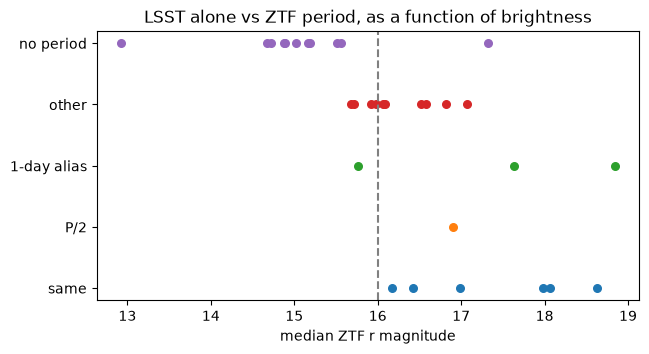

In [25]:
fig, ax = plt.subplots(figsize=(7, 3.5))
lsst_rel = rel["LSST, multi-harmonic"]
for r in ["same", "2P", "P/2", "1-day alias", "other", "no period"]:
    m = lsst_rel == r
    if m.any():
        ax.scatter(sample.ztf_r_mag[m], np.full(m.sum(), r), s=30)
ax.axvline(16, color="0.5", ls="--")
ax.set_xlabel("median ZTF r magnitude")
ax.set_title("LSST alone vs ZTF period, as a function of brightness");

Almost all the stars for which LSST finds no period are **brighter than r ≈ 16**: Rubin's 8.4 m mirror
**saturates** bright stars in a 30 s exposure, while ZTF (1.2 m) measures them well. Just below that limit
(r ≈ 16–17) LSST often finds an unrelated ("other") period, while all the stars with matching periods are fainter
than r ≈ 16. The two surveys cover complementary brightness ranges, and for bright stars ZTF provides the period on
its own.

Finally, the comparison on a plot. Disagreements between methods do not scatter randomly: they line up on the
alias curves.

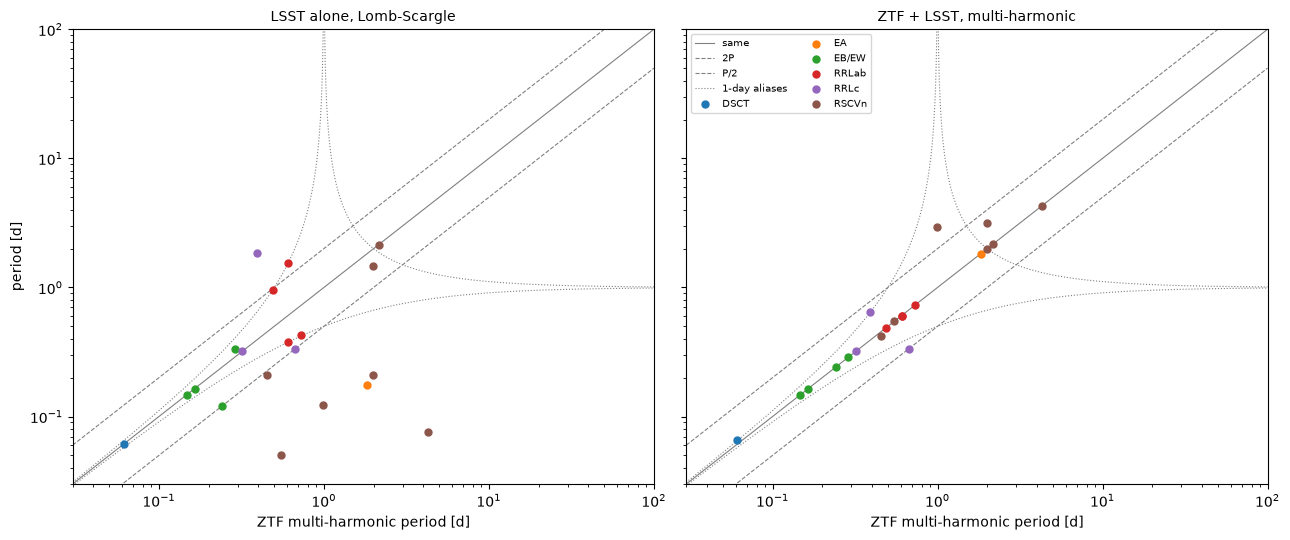

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
period_scatter(axes[0], sample.P_best_ztf, sample.P_ls_lsst, sample.class_name,
               "ZTF multi-harmonic period [d]", "period [d]", "LSST alone, Lomb-Scargle")
period_scatter(axes[1], sample.P_best_ztf, sample.P_best_comb, sample.class_name,
               "ZTF multi-harmonic period [d]", "", "ZTF + LSST, multi-harmonic")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout();

With ZTF + LSST and the multi-harmonic method, most stars land on the "same" line; the rest sit on alias curves.
Here are the stars where ZTF + LSST gives a period and it does **not** agree with ZTF alone:

In [27]:
sample[(rel["ZTF+LSST, multi-harmonic"] != "same") & sample.P_best_comb.notna()][
    ["ztf_name", "class_name", "ztf_r_mag", "P_best_ztf", "P_best_lsst", "P_best_comb"]].round(4)

,ztf_name,class_name,ztf_r_mag,P_best_ztf,P_best_lsst,P_best_comb
0,ZTF19aarswrn,DSCT,18.8383,0.0613,0.0654,0.0654
20,ZTF18acurdih,RRLc,16.9023,0.6694,0.3347,0.3347
22,ZTF19aakzaeb,RRLc,17.6298,0.3924,0.6466,0.6469
23,ZTF20aaplegi,RSCVn,17.0643,1.9934,3.1768,3.1604
24,ZTF24aabbxjv,RSCVn,15.9214,0.9883,0.2479,2.9431
30,ZTF19aatjrpn,RSCVn,16.8130,0.4545,0.4171,0.4171


Compare with the known period ranges of RR Lyrae (RRc: ~0.2–0.45 d, RRab: ~0.45–1 d). For **ZTF18acurdih**, an RRc
star, ZTF alone found 0.669 d, twice the period, while LSST and the combination find 0.3347 d, right in the RRc range:
here the extra LSST bands and phases broke a ZTF alias. Other cases (e.g. ZTF19aakzaeb) are less clear: see
exercise 4.

## 7. The Bailey diagram

RR Lyrae stars pulsate in the fundamental mode (**RRab**: longer periods, large asymmetric amplitudes) or in the
first overtone (**RRc**: shorter periods, smaller, more sinusoidal amplitudes). The period–amplitude plane, the
**Bailey diagram**, separates them. We use the ZTF+LSST period and the ALeRCE `Amplitude` feature in ZTF g
(half of the peak-to-peak amplitude, in magnitudes):

,ztf_name,class_name,probability,P_best_ztf,P_best_comb,P,amp_g
12,ZTF17aaanrvs,RRLab,0.842,0.6053,0.6053,0.6053,0.4859
13,ZTF17aabmiht,RRLab,0.816,0.5423,NaN,0.5423,0.5464
14,ZTF17aaajhdq,RRLab,0.810,0.5566,NaN,0.5566,0.5650
15,ZTF17aaansag,RRLab,0.796,0.7289,0.7289,0.7289,0.4712
16,ZTF17aaapjvn,RRLab,0.770,0.6081,NaN,0.6081,0.4133
17,ZTF17aabhbva,RRLab,0.762,0.4889,0.4889,0.4889,0.7698
18,ZTF18acqlouv,RRLab,0.508,0.6061,0.6061,0.6061,0.3601
19,ZTF17aabofpf,RRLc,0.784,0.3210,0.3210,0.3210,0.3241
20,ZTF18acurdih,RRLc,0.602,0.6694,0.3347,0.3347,0.3202
21,ZTF19aaejpta,RRLc,0.536,0.3308,NaN,0.3308,0.3694


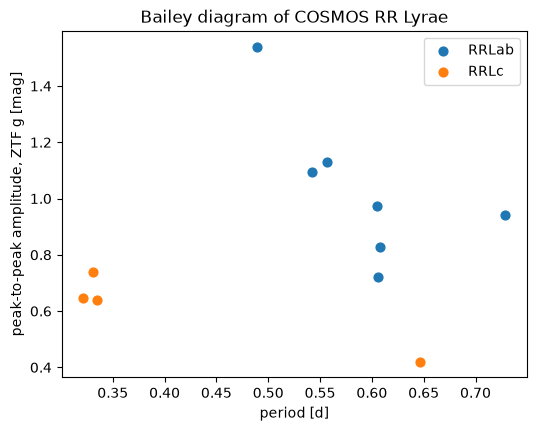

In [28]:
rr = sample[sample.class_name.isin(["RRLab", "RRLc"])].copy()
amp = am.tap_query(f"""
    SELECT oid, feature_value AS amplitude
    FROM alerce_tap.feature
    WHERE sid = 0 AND feature_id = {am.feature_ids(0, ['Amplitude'])['Amplitude']}
      AND band = 1 AND oid IN ({", ".join(map(str, rr.ztf_oid))})
""").set_index("oid").amplitude
rr["amp_g"] = rr.ztf_oid.map(amp)
rr["P"] = rr.P_best_comb.fillna(rr.P_best_ztf)        # ZTF alone where LSST saturates

fig, ax = plt.subplots(figsize=(6, 4.5))
for cls, g in rr.groupby("class_name"):
    ax.scatter(g.P, 2 * g.amp_g, s=40, label=cls)
ax.set_xlabel("period [d]")
ax.set_ylabel("peak-to-peak amplitude, ZTF g [mag]")
ax.set_title("Bailey diagram of COSMOS RR Lyrae")
ax.legend()
rr[["ztf_name", "class_name", "probability", "P_best_ztf", "P_best_comb", "P", "amp_g"]].round(4)

The RRab stars (P ≈ 0.49–0.73 d) show the classic trend: the longer the period, the smaller the amplitude. The RRc
stars cluster at P ≈ 0.32–0.33 d with smaller amplitudes. One "RRc", ZTF19aakzaeb (classifier probability only 0.28),
sits at 0.65 d with a low amplitude: either its period or its class is wrong — the kind of object that deserves a
closer look.

## 8. ✏️ Exercises

1. **(easy)** Fold the ZTF and LSST light curves of `ZTF17aabhbva` at 0.48888 d in *magnitudes* with
   `am.plot_folded(lc, period, flux="sci")` (use `lc_ztf` and `lc_a`). Which LSST band has the largest amplitude?
   Is that what you expect for a pulsating star?
2. **(easy)** Pick an eclipsing binary (`EB/EW`) from `sample` and fold it at `P_ls_ztf` and at `P_best_ztf` with
   `plot_fold(prepare(lc), P, ax)`. Why is the Lomb-Scargle period half of the true one?
3. **(medium)** Run `find_period` on LSST diaObjects A and B of the RR Lyrae *separately*. Do they agree? Which one
   has more nights of data?
4. **(medium)** Choose a star from the last table of section 6.2 and decide, by folding both light curves at both
   periods and using the RR Lyrae period ranges, which period is right. Look at it in the explorer with
   `am.show_link(oid, "ztf")`.
5. **(challenge)** Add the RS CVn stars to the Bailey diagram. Where do they fall? Then repeat section 6 for another
   region where ZTF and LSST overlap (e.g. RA = 189°, Dec = +8.6°). Why are there fewer LSST epochs outside the
   deep-drilling fields?

In [29]:
# your code here

**Back to the start:** [00 · Introduction](00_introduction.ipynb)